# XGBoost

In [81]:
import pandas as pd
import numpy as np

import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split

import xgboost as xgb

%matplotlib inline

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
from EDA_and_modeling.functional_files import _featuring, _data, _model_impex, _evaluating
import importlib
importlib.reload(_data)
importlib.reload(_featuring)
importlib.reload(_evaluating)
importlib.reload(_model_impex)

print('Libraries loaded!')

pd.set_option('display.max_rows', None)      # all rows
pd.set_option('display.max_columns', None)   # all columns
pd.set_option('display.width', None)         # no line wrapping
pd.set_option('display.max_colwidth', None)  # don't truncate cell contents

Data File: Libraries loaded!
Featuring File: Libraries loaded!
Evaluating File: Libraries loaded!
Model Impex File: Libraries loaded!
Libraries loaded!


In [4]:
def sp(two_lines = True):
    print("==========================")
    if (two_lines):
        print()
        print("==========================")

## Data

In [82]:
df, _ = _data.get_data('1')

In [6]:
x = df.drop(columns='is_fraud')
y = df['is_fraud']
x_temp_raw, x_test_raw, y_temp, y_test = train_test_split(x, y, test_size=0.2, stratify=y, random_state=42)
x_train_raw, x_val_raw, y_train, y_val = train_test_split(x_temp_raw, y_temp, test_size=0.25, stratify=y_temp,
                                                          random_state=42)
x_train_raw = _featuring.simple(x_train_raw)
x_val_raw = _featuring.simple(x_val_raw)
x_test_raw = _featuring.simple(x_test_raw)

## Model

In [32]:
IMPORT_MODEL = False
PARAMETERS_ADJUSTMENT = True
model_name = "13_xgb"

best_eta = 0.3
best_max_depth = 6
best_mcw = 1

In [10]:
if IMPORT_MODEL:
    dv, _ = _model_impex.import_model(model_name)
    x_train = _model_impex.dv_transform(dv, x_train_raw)
    x_val = _model_impex.dv_transform(dv, x_val_raw)
    # x_test = _model_impex.dv_transform(dv, x_test_raw)
else:
    dv = _model_impex.dv_initializing(x_train_raw)
    x_train = _model_impex.dv_transform(dv, x_train_raw)
    x_val = _model_impex.dv_transform(dv, x_val_raw)
    # x_test = _model_impex.dv_transform(dv, x_test_raw)

In [12]:
features = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(x_train, label=y_train, feature_names=features)
dval = xgb.DMatrix(x_val, label=y_val, feature_names=features)

### Parameters adjustment

In [27]:
watchlist = [(dtrain, 'train'), (dval, 'val')]

In [31]:
if PARAMETERS_ADJUSTMENT:
    # Train XGBoost models for each eta and store AUC results
    scores = {} # dictionary to store results for each eta
    etas = [0.01, 0.05, 0.1, 0.3, 1.0] # list of parameter values. in this case it is 'eta'.

    for eta in etas:
        evals_result = {}

        xgb_params = {
            'eta': eta,
            'max_depth': 6,
            'min_child_weight': 1,

            'objective': 'binary:logistic',
            'eval_metric': 'auc',

            'nthread': 8,
            'seed': 42,
            'verbosity': 1
        }

        model = xgb.train(
            xgb_params,
            dtrain,
            evals=watchlist,
            verbose_eval=0,
            num_boost_round=1000,
            evals_result=evals_result
        )

        columns = ['iter', 'train_auc', 'val_auc']
        val_aucs = list(evals_result['val'].values())[0]

        key = f'{eta}'
        scores[key] = max(val_aucs)

        print("eta:", eta)

eta: 0.01
eta: 0.05
eta: 0.1
eta: 0.3
eta: 1.0


In [53]:
if PARAMETERS_ADJUSTMENT:
    df_scores = pd.DataFrame.from_dict(scores, orient='index', columns=['auc'])
    df_scores = df_scores.sort_values(by='auc', ascending=False)
    best_eta = 0.05 #float(df_scores['auc'].idxmax())
    display(df_scores)

,auc
1,0.876745
2,0.876745
3,0.876745
4,0.876745
5,0.876745
6,0.876745
7,0.876745
8,0.876745
9,0.876745


In [55]:
if PARAMETERS_ADJUSTMENT:
    # Train XGBoost models for each eta and store AUC results
    scores = {} # dictionary to store results for each eta
    max_depths = np.arange(1, 10, 1) # list of parameter values. in this case it is 'eta'.

    for depth in max_depths:
        evals_result = {}

        xgb_params = {
            'eta': best_eta,
            'max_depth': max_depth,
            'min_child_weight': 1,

            'objective': 'binary:logistic',
            'eval_metric': 'auc',

            'nthread': 8,
            'seed': 42,
            'verbosity': 1
        }

        model = xgb.train(
            xgb_params,
            dtrain,
            evals=watchlist,
            verbose_eval=0,
            num_boost_round=1000,
            evals_result=evals_result
        )

        columns = ['iter', 'train_auc', 'val_auc']
        val_aucs = list(evals_result['val'].values())[0]

        key = f'{depth}'
        scores[key] = max(val_aucs)

        print("Depth:", depth)

Depth: 1


In [56]:
if PARAMETERS_ADJUSTMENT:
    df_scores = pd.DataFrame.from_dict(scores, orient='index', columns=['auc'])
    df_scores = df_scores.sort_values(by='auc', ascending=False)
    best_max_depth = 10 # int(df_scores['auc'].idxmax())
    display(df_scores)

,auc
1,0.942914


In [57]:
if PARAMETERS_ADJUSTMENT:
    # Train XGBoost models for each eta and store AUC results
    scores = {} # dictionary to store results for each eta
    options = np.arange(1, 100, 5) # list of parameter values. in this case it is 'eta'.

    for mcw in options:
        evals_result = {}

        xgb_params = {
            'eta': best_eta,
            'max_depth': best_max_depth,
            'min_child_weight': mcw,

            'objective': 'binary:logistic',
            'eval_metric': 'auc',

            'nthread': 8,
            'seed': 42,
            'verbosity': 1
        }

        model = xgb.train(
            xgb_params,
            dtrain,
            evals=watchlist,
            verbose_eval=0,
            num_boost_round=1000,
            evals_result=evals_result
        )

        columns = ['iter', 'train_auc', 'val_auc']
        val_aucs = list(evals_result['val'].values())[0]

        key = f'{mcw}'
        scores[key] = max(val_aucs)

        print("MCW:", mcw)

MCW: 1
MCW: 6
MCW: 11
MCW: 16
MCW: 21
MCW: 26
MCW: 31
MCW: 36
MCW: 41
MCW: 46
MCW: 51
MCW: 56
MCW: 61
MCW: 66
MCW: 71
MCW: 76
MCW: 81
MCW: 86
MCW: 91
MCW: 96


In [72]:
if PARAMETERS_ADJUSTMENT:
    df_scores = pd.DataFrame.from_dict(scores, orient='index', columns=['auc'])
    df_scores = df_scores.sort_values(by='auc', ascending=False)
    best_mcw = int(df_scores['auc'].idxmax()) - 1
    display(df_scores.head())

,auc
36,0.942969
31,0.942939
26,0.942548
21,0.942228
16,0.942082


In [83]:
if IMPORT_MODEL:
    _, model = _mode_impex.import_model(model_name)
else:
    xgb_params = {
        'eta': best_eta,
        'max_depth': best_max_depth,
        'min_child_weight': best_mcw,

        'objective': 'binary:logistic',
        'nthread': 8,

        'seed': 42,
        'verbosity': 1,
    }
    model = xgb.train(xgb_params, dtrain, num_boost_round=1000)
    _model_impex.export_model(model_name, dv, model)

ROC AUC: 0.9394615863656766
PR AUC: 0.48299882145065276


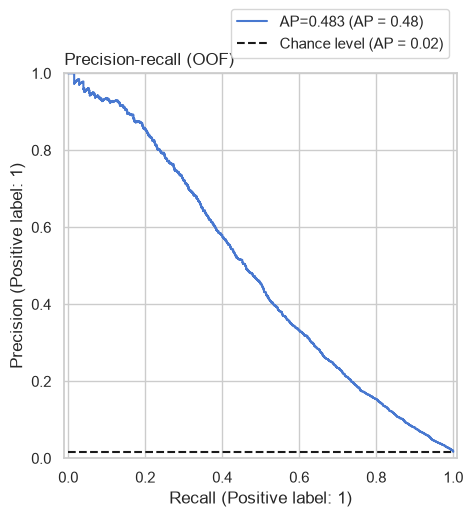

In [84]:
prediction = model.predict(dval)
_evaluating.full_score(y_val, prediction)
_evaluating.plot_pr_auc(y_val, prediction)

#### Conclusion 6
XGBoost model shows itself to be slightly more successful in repsect to AUC score

In [88]:
_, df_test_raw = _data.get_data('1')
df_test = _model_impex.dv_transform(dv, df_test_raw)
dtest = xgb.DMatrix(df_test, feature_names=features)
predicted = model.predict(dtest)
_data.kaggle_solution_import(predicted, '13')